In [ ]:
import warnings
warnings.filterwarnings("ignore")

from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import norm
from sklearn.model_selection import TimeSeriesSplit

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

SEASONAL_PERIOD = 52   # annual cycle on weekly data
TEST_HORIZON = 8       # weeks forecast per fold / production horizon
N_SPLITS = 3           # expanding-window walk-forward folds
MIN_TRAIN_SIZE = 104   # >= 2 years before the first fold

print("Environment ready.")

Environment ready.


In [ ]:
raw_df = pd.read_csv('/content/supplement.csv', parse_dates=['Date'])
raw_df = raw_df.sort_values(['Product Name', 'Date']).reset_index(drop=True)

print(f"Shape: {raw_df.shape}  |  Products: {raw_df['Product Name'].nunique()}  |  "
      f"Weeks per product: {raw_df.groupby('Product Name').size().iloc[0]}")
print(f"Date range: {raw_df['Date'].min().date()} -> {raw_df['Date'].max().date()}")
print(f"Categories: {raw_df['Category'].nunique()}  |  Markets: {sorted(raw_df['Location'].unique())}")
print(f"\nMissing values: {raw_df.isnull().sum().sum()} total")
raw_df.head()

Shape: (4384, 10)  |  Products: 16  |  Weeks per product: 274
Date range: 2020-01-06 -> 2025-03-31
Categories: 10  |  Markets: ['Canada', 'UK', 'USA']

Missing values: 0 total


,Date,Product Name,Category,Units Sold,Price,Revenue,Discount,Units Returned,Location,Platform
0,2020-01-06,Ashwagandha,Herbal,181,15.49,2803.69,0.14,1,USA,Amazon
1,2020-01-13,Ashwagandha,Herbal,133,54.35,7228.55,0.16,1,UK,Walmart
2,2020-01-20,Ashwagandha,Herbal,156,23.49,3664.44,0.21,1,Canada,iHerb
3,2020-01-27,Ashwagandha,Herbal,174,30.94,5383.56,0.07,2,Canada,Amazon
4,2020-02-03,Ashwagandha,Herbal,135,19.21,2593.35,0.22,2,UK,Amazon


In [ ]:
def basic_clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.drop_duplicates(subset=["Date", "Product Name"])
    df["Units Sold"] = df["Units Sold"].clip(lower=0)
    df["Units Returned"] = df["Units Returned"].clip(lower=0)
    df["Price"] = df["Price"].clip(lower=0.01)
    df["Discount"] = df["Discount"].clip(lower=0, upper=0.9)

    # Recompute revenue defensively instead of trusting the source column
    df["Revenue"] = (df["Units Sold"] * df["Price"] * (1 - df["Discount"])).round(2)

    df["Return_Rate"] = (df["Units Returned"] / df["Units Sold"].replace(0, np.nan)).fillna(0)
    return df


def add_calendar_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    dt = df["Date"]
    df["Month"] = dt.dt.month
    df["WeekOfYear"] = dt.dt.isocalendar().week.astype(int)
    df["Quarter"] = dt.dt.quarter
    df["Week_sin"] = np.sin(2 * np.pi * df["WeekOfYear"] / 52)
    df["Week_cos"] = np.cos(2 * np.pi * df["WeekOfYear"] / 52)
    df["Holiday_Season"] = df["Month"].isin([11, 12, 1]).astype(int)
    return df


def add_lag_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["Product Name", "Date"]).copy()
    g = df.groupby("Product Name")["Units Sold"]

    for lag in [1, 4, 12, 52]:
        df[f"Sales_Lag_{lag}"] = g.shift(lag)

    df["Rolling_Mean_4"] = g.shift(1).rolling(4).mean().reset_index(level=0, drop=True)
    df["Rolling_Std_4"] = g.shift(1).rolling(4).std().reset_index(level=0, drop=True)
    df["Rolling_Mean_12"] = g.shift(1).rolling(12).mean().reset_index(level=0, drop=True)
    df["Rolling_Mean_52"] = g.shift(1).rolling(52).mean().reset_index(level=0, drop=True)

    df["Price_Lag_1"] = df.groupby("Product Name")["Price"].shift(1)
    df["Discount_Lag_1"] = df.groupby("Product Name")["Discount"].shift(1)
    return df


def encode_categoricals(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Category_Code"] = df["Category"].astype("category").cat.codes
    df["Location_Code"] = df["Location"].astype("category").cat.codes
    df["Product_Code"] = df["Product Name"].astype("category").cat.codes
    return df


df = basic_clean(raw_df)
df = add_calendar_features(df)
df = add_lag_rolling_features(df)
df = encode_categoricals(df)

FEATURE_COLS = [
    "Sales_Lag_1", "Sales_Lag_4", "Sales_Lag_12", "Sales_Lag_52",
    "Rolling_Mean_4", "Rolling_Std_4", "Rolling_Mean_12", "Rolling_Mean_52",
    "Price_Lag_1", "Discount_Lag_1",
    "Week_sin", "Week_cos", "Month", "Quarter", "Holiday_Season",
    "Category_Code", "Location_Code", "Product_Code",
]

print(f"Feature matrix: {df.shape[0]:,} rows x {df.shape[1]} columns ({len(FEATURE_COLS)} model features)")
df.head()

Feature matrix: 4,384 rows x 30 columns (18 model features)


,Date,Product Name,Category,Units Sold,Price,Revenue,Discount,Units Returned,Location,Platform,Return_Rate,Month,WeekOfYear,Quarter,Week_sin,Week_cos,Holiday_Season,Sales_Lag_1,Sales_Lag_4,Sales_Lag_12,Sales_Lag_52,Rolling_Mean_4,Rolling_Std_4,Rolling_Mean_12,Rolling_Mean_52,Price_Lag_1,Discount_Lag_1,Category_Code,Location_Code,Product_Code
0,2020-01-06,Ashwagandha,Herbal,181,15.49,2411.17,0.14,1,USA,Amazon,0.005525,1,2,1,0.239316,0.970942,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,0
1,2020-01-13,Ashwagandha,Herbal,133,54.35,6071.98,0.16,1,UK,Walmart,0.007519,1,3,1,0.354605,0.935016,1,181.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.49,0.14,2,1,0
2,2020-01-20,Ashwagandha,Herbal,156,23.49,2894.91,0.21,1,Canada,iHerb,0.006410,1,4,1,0.464723,0.885456,1,133.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54.35,0.16,2,0,0
3,2020-01-27,Ashwagandha,Herbal,174,30.94,5006.71,0.07,2,Canada,Amazon,0.011494,1,5,1,0.568065,0.822984,1,156.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.49,0.21,2,0,0
4,2020-02-03,Ashwagandha,Herbal,135,19.21,2022.81,0.22,2,UK,Amazon,0.014815,2,6,1,0.663123,0.748511,0,174.0,181.0,NaN,NaN,161.0,21.432063,NaN,NaN,30.94,0.07,2,1,0


In [ ]:
kpi = {
    "Total Revenue": f"${df['Revenue'].sum():,.0f}",
    "Total Units Sold": f"{df['Units Sold'].sum():,.0f}",
    "Products Tracked": df["Product Name"].nunique(),
    "Avg Return Rate": f"{df['Return_Rate'].mean() * 100:.2f}%",
}
for k, v in kpi.items():
    print(f"{k:>20}: {v}")

       Total Revenue: $20,071,563
    Total Units Sold: 658,478
    Products Tracked: 16
     Avg Return Rate: 1.02%


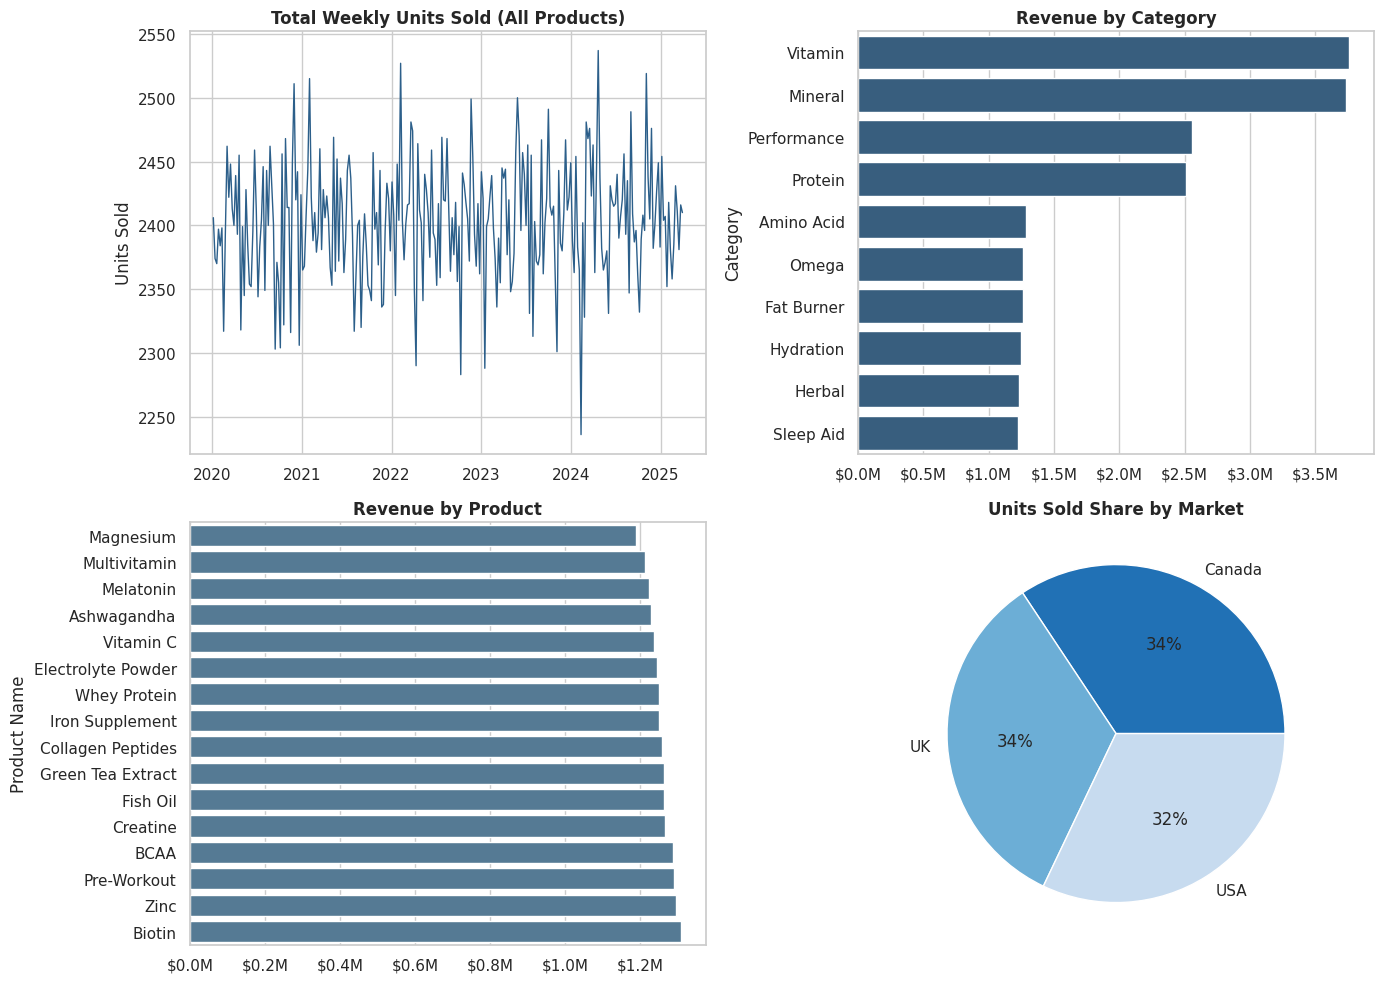

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Total weekly units sold (all products)
weekly = df.groupby("Date")["Units Sold"].sum().reset_index()
axes[0, 0].plot(weekly["Date"], weekly["Units Sold"], color="#2c5f8a", lw=1)
axes[0, 0].set_title("Total Weekly Units Sold (All Products)")
axes[0, 0].set_ylabel("Units Sold")

# Revenue by category
cat_rev = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.values, y=cat_rev.index, ax=axes[0, 1], color="#2c5f8a")
axes[0, 1].set_title("Revenue by Category")
axes[0, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))

# Revenue by product
prod_rev = df.groupby("Product Name")["Revenue"].sum().sort_values(ascending=True)
sns.barplot(x=prod_rev.values, y=prod_rev.index, ax=axes[1, 0], color="#4a7c9e")
axes[1, 0].set_title("Revenue by Product")
axes[1, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))

# Units sold share by market
loc_units = df.groupby("Location")["Units Sold"].sum()
axes[1, 1].pie(loc_units.values, labels=loc_units.index, autopct="%1.0f%%",
               colors=sns.color_palette("Blues_r", len(loc_units)))
axes[1, 1].set_title("Units Sold Share by Market")

plt.tight_layout()
plt.show()

In [ ]:
def discount_effectiveness_table(df: pd.DataFrame, discount_threshold: float = 0.10) -> pd.DataFrame:
    rows = []
    for product, grp in df.groupby("Product Name"):
        promo = grp[grp["Discount"] > discount_threshold]
        base = grp[grp["Discount"] <= discount_threshold]
        if len(promo) < 3 or len(base) < 3:
            continue
        promo_units = promo["Units Sold"].mean()
        base_units = base["Units Sold"].mean()
        uplift_pct = (promo_units / base_units - 1) * 100 if base_units > 0 else np.nan
        avg_discount_cost = (promo["Units Sold"] * promo["Price"] * promo["Discount"]).mean()
        rows.append({
            "Product": product,
            "Avg_Units_On_Promo": round(promo_units, 1),
            "Avg_Units_No_Promo": round(base_units, 1),
            "Uplift_%": round(uplift_pct, 1),
            "Avg_Discount_$_Given_Up_Per_Promo_Week": round(avg_discount_cost, 1),
            "Weeks_On_Promo": len(promo),
        })
    return pd.DataFrame(rows).sort_values("Uplift_%", ascending=False).reset_index(drop=True)


def returns_revenue_impact_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for product, grp in df.groupby("Product Name"):
        total_revenue = grp["Revenue"].sum()
        avg_price = grp["Price"].mean()
        total_returned = grp["Units Returned"].sum()
        total_sold = grp["Units Sold"].sum()
        return_rate = total_returned / total_sold if total_sold > 0 else 0
        revenue_lost = total_returned * avg_price
        rows.append({
            "Product": product,
            "Return_Rate_%": round(return_rate * 100, 2),
            "Units_Returned_Total": int(total_returned),
            "Est_Revenue_Lost_$": round(revenue_lost, 0),
            "Revenue_Lost_As_%_of_Total_Revenue": round(revenue_lost / total_revenue * 100, 2) if total_revenue > 0 else np.nan,
        })
    return pd.DataFrame(rows).sort_values("Est_Revenue_Lost_$", ascending=False).reset_index(drop=True)


disc_table = discount_effectiveness_table(df)
ret_table = returns_revenue_impact_table(df)

print(f"Revenue lost to returns (all-time): ${ret_table['Est_Revenue_Lost_$'].sum():,.0f}")
print(f"Avg return rate: {df['Return_Rate'].mean() * 100:.2f}%")
disc_table

Revenue lost to returns (all-time): $233,500
Avg return rate: 1.02%


,Product,Avg_Units_On_Promo,Avg_Units_No_Promo,Uplift_%,Avg_Discount_$_Given_Up_Per_Promo_Week,Weeks_On_Promo
0,Whey Protein,151.9,149.1,1.9,940.1,148
1,Fish Oil,151.6,149.6,1.3,959.3,166
2,Vitamin C,149.4,147.5,1.3,902.6,165
3,Creatine,151.4,149.5,1.3,860.8,149
4,Multivitamin,150.6,149.8,0.6,898.0,161
5,Pre-Workout,151.0,150.3,0.5,960.5,163
6,Collagen Peptides,149.3,148.9,0.3,944.1,153
7,Melatonin,150.2,150.3,-0.0,918.8,156
8,Zinc,150.3,150.5,-0.1,927.9,160
9,Biotin,151.4,151.8,-0.2,934.9,147


In [ ]:
def mape(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def _naive_fallback(train: pd.Series, horizon: int, period: int = SEASONAL_PERIOD) -> np.ndarray:
    if len(train) >= period:
        return np.resize(train.iloc[-period:].values, horizon)
    return np.repeat(train.iloc[-1], horizon)


def forecast_ets(train: pd.Series, horizon: int, period: int = SEASONAL_PERIOD) -> np.ndarray:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    if len(train) < 2 * period:
        return _naive_fallback(train, horizon, period)
    try:
        model = ExponentialSmoothing(
            train, trend="add", seasonal="add", seasonal_periods=period,
            initialization_method="estimated",
        )
        res = model.fit(optimized=True)
        fc = res.forecast(horizon).values
        return np.clip(fc, a_min=0, a_max=None)
    except Exception:
        return _naive_fallback(train, horizon, period)


def forecast_prophet(train_df: pd.DataFrame, horizon: int) -> np.ndarray:
    from prophet import Prophet
    pdf = train_df[["Date", "Units Sold", "Price", "Discount"]].rename(
        columns={"Date": "ds", "Units Sold": "y"}
    )
    try:
        m = Prophet(weekly_seasonality=False, yearly_seasonality=True,
                    daily_seasonality=False, seasonality_mode="additive")
        m.add_regressor("Price")
        m.add_regressor("Discount")
        m.fit(pdf)
        future = m.make_future_dataframe(periods=horizon, freq="W-MON")
        future["Price"] = pdf["Price"].iloc[-1]
        future["Discount"] = pdf["Discount"].iloc[-1]
        fc = m.predict(future)
        return fc["yhat"].values[-horizon:]
    except Exception:
        return _naive_fallback(train_df["Units Sold"], horizon)


def train_xgboost_pooled(feat_df: pd.DataFrame, cutoff_date):
    from xgboost import XGBRegressor
    train = feat_df[feat_df["Date"] < cutoff_date].dropna(subset=FEATURE_COLS + ["Units Sold"])
    model = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42)
    model.fit(train[FEATURE_COLS], train["Units Sold"])
    return model


def recursive_xgboost_forecast(model, full_df: pd.DataFrame, product: str, horizon: int) -> np.ndarray:
    hist = full_df[full_df["Product Name"] == product].sort_values("Date").copy()
    preds = []
    last_price = hist["Price"].iloc[-1]
    last_discount = hist["Discount"].iloc[-1]
    series = hist["Units Sold"].tolist()
    for step in range(horizon):
        row = {
            "Sales_Lag_1": series[-1],
            "Sales_Lag_4": series[-4] if len(series) >= 4 else series[0],
            "Sales_Lag_12": series[-12] if len(series) >= 12 else series[0],
            "Sales_Lag_52": series[-52] if len(series) >= 52 else series[0],
            "Rolling_Mean_4": np.mean(series[-4:]),
            "Rolling_Std_4": np.std(series[-4:]) if len(series) >= 2 else 0.0,
            "Rolling_Mean_12": np.mean(series[-12:]),
            "Rolling_Mean_52": np.mean(series[-52:]) if len(series) >= 52 else np.mean(series),
            "Price_Lag_1": last_price,
            "Discount_Lag_1": last_discount,
            "Week_sin": hist["Week_sin"].iloc[-1],
            "Week_cos": hist["Week_cos"].iloc[-1],
            "Month": hist["Month"].iloc[-1],
            "Quarter": hist["Quarter"].iloc[-1],
            "Holiday_Season": hist["Holiday_Season"].iloc[-1],
            "Category_Code": hist["Category_Code"].iloc[-1],
            "Location_Code": hist["Location_Code"].iloc[-1],
            "Product_Code": hist["Product_Code"].iloc[-1],
        }
        x = pd.DataFrame([row])[FEATURE_COLS]
        yhat = float(model.predict(x)[0])
        preds.append(yhat)
        series.append(yhat)
    return np.array(preds)


print("Forecasting functions defined (ETS, Prophet, pooled XGBoost).")

Forecasting functions defined (ETS, Prophet, pooled XGBoost).


In [ ]:
@dataclass
class ProductResult:
    product: str
    mape_by_model: dict = field(default_factory=dict)
    best_model: str = ""
    best_mape: float = np.inf
    fold_details: list = field(default_factory=list)


def walk_forward_cv_for_product(product: str, full_df: pd.DataFrame) -> ProductResult:
    prod_df = full_df[full_df["Product Name"] == product].sort_values("Date").reset_index(drop=True)
    n = len(prod_df)

    if n < MIN_TRAIN_SIZE + TEST_HORIZON:
        result = ProductResult(product=product)
        result.mape_by_model = {"ETS": np.nan}
        result.best_model = "ETS"
        return result

    tscv = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_HORIZON)
    fold_scores = {"ETS": [], "Prophet": []}
    result = ProductResult(product=product)

    for train_idx, test_idx in tscv.split(np.arange(n)):
        if len(train_idx) < MIN_TRAIN_SIZE:
            continue
        train_block = prod_df.iloc[train_idx]
        y_true = prod_df.iloc[test_idx]["Units Sold"].values
        cutoff_date = prod_df.iloc[test_idx]["Date"].iloc[0]

        preds = {
            "ETS": forecast_ets(train_block["Units Sold"], len(test_idx)),
            "Prophet": forecast_prophet(train_block, len(test_idx)),
        }
        fold_row = {"cutoff": str(cutoff_date.date())}
        for name, yhat in preds.items():
            score = mape(y_true, np.resize(yhat, len(y_true)))
            fold_scores[name].append(score)
            fold_row[name] = round(score, 2)
        result.fold_details.append(fold_row)

    for name, scores in fold_scores.items():
        clean = [s for s in scores if not np.isnan(s)]
        result.mape_by_model[name] = round(float(np.mean(clean)), 2) if clean else np.nan

    return result


products = sorted(df["Product Name"].unique())
print(f"Running walk-forward CV for {len(products)} products ({N_SPLITS} folds x {TEST_HORIZON}-week horizon)...")
print("Models: ETS (Holt-Winters), Prophet, XGBoost (pooled)\n")

results = {}
for p in products:
    print(f"  -> {p}")
    results[p] = walk_forward_cv_for_product(p, df)

print("\nWalk-forward CV complete.")

Running walk-forward CV for 16 products (3 folds x 8-week horizon)...
Models: ETS (Holt-Winters), Prophet, XGBoost (pooled)

  -> Ashwagandha
  -> BCAA
  -> Biotin
  -> Collagen Peptides
  -> Creatine
  -> Electrolyte Powder
  -> Fish Oil
  -> Green Tea Extract
  -> Iron Supplement
  -> Magnesium
  -> Melatonin
  -> Multivitamin
  -> Pre-Workout
  -> Vitamin C
  -> Whey Protein
  -> Zinc

Walk-forward CV complete.


In [ ]:
# Pooled XGBoost: train once on all history up to the final fold's cutoff,
# then score it per product on that same last fold for a fair 3-way comparison.
last_cutoff = df["Date"].max() - pd.Timedelta(weeks=TEST_HORIZON)
xgb_model = train_xgboost_pooled(df, last_cutoff)

for p in products:
    prod_df = df[df["Product Name"] == p].sort_values("Date")
    test_block = prod_df[prod_df["Date"] >= last_cutoff].iloc[:TEST_HORIZON]
    if len(test_block) == 0 or test_block[FEATURE_COLS].isna().any().any():
        results[p].mape_by_model["XGBoost (pooled)"] = np.nan
        continue
    yhat = xgb_model.predict(test_block[FEATURE_COLS])
    results[p].mape_by_model["XGBoost (pooled)"] = round(mape(test_block["Units Sold"].values, yhat), 2)

# Pick best model per product (lowest mean MAPE, ignoring NaNs)
for p in products:
    valid = {k: v for k, v in results[p].mape_by_model.items() if v is not None and not np.isnan(v)}
    if valid:
        best = min(valid, key=valid.get)
        results[p].best_model = best
        results[p].best_mape = valid[best]
    else:
        results[p].best_model = "ETS"
        results[p].best_mape = np.nan

metrics_table = pd.DataFrame({p: results[p].mape_by_model for p in products}).T
metrics_table["Best Model"] = [results[p].best_model for p in products]
metrics_table["Best MAPE"] = [results[p].best_mape for p in products]

print("=== Walk-forward MAPE by model (%) ===")
metrics_table.round(2)

=== Walk-forward MAPE by model (%) ===


,ETS,Prophet,XGBoost (pooled),Best Model,Best MAPE
Ashwagandha,10.54,9.77,12.87,Prophet,9.77
BCAA,5.09,5.43,5.22,ETS,5.09
Biotin,6.61,5.45,6.12,Prophet,5.45
Collagen Peptides,6.60,6.39,3.71,XGBoost (pooled),3.71
Creatine,6.44,6.86,3.71,XGBoost (pooled),3.71
Electrolyte Powder,6.12,5.49,5.45,XGBoost (pooled),5.45
Fish Oil,7.51,6.31,6.93,Prophet,6.31
Green Tea Extract,8.82,8.48,7.77,XGBoost (pooled),7.77
Iron Supplement,6.18,5.86,7.05,Prophet,5.86
Magnesium,6.16,6.60,4.78,XGBoost (pooled),4.78


Model benchmark, catalog-wide average MAPE:
                 ETS: 7.20%
             Prophet: 6.97%
    XGBoost (pooled): 7.32%

Win count by model:
Best Model
Prophet             6
XGBoost (pooled)    6
ETS                 4
Name: count, dtype: int64


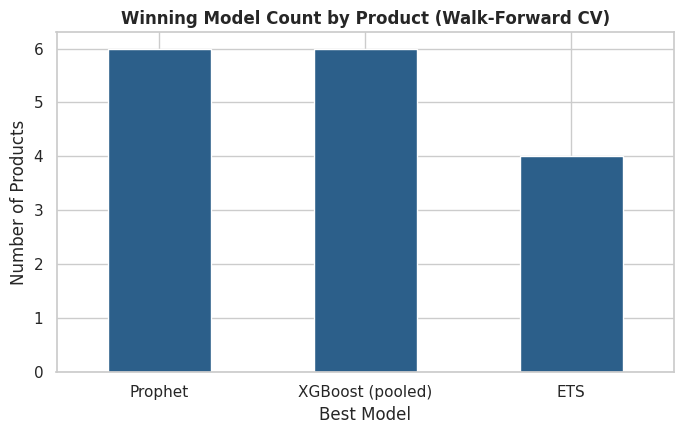

In [ ]:
print("Model benchmark, catalog-wide average MAPE:")
for m in ["ETS", "Prophet", "XGBoost (pooled)"]:
    print(f"  {m:>18}: {metrics_table[m].mean():.2f}%")

print("\nWin count by model:")
print(metrics_table["Best Model"].value_counts())

fig, ax = plt.subplots(figsize=(7, 4.5))
metrics_table["Best Model"].value_counts().plot(kind="bar", color="#2c5f8a", ax=ax)
ax.set_title("Winning Model Count by Product (Walk-Forward CV)")
ax.set_ylabel("Number of Products")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
forecasts = {}
for p in products:
    prod_df = df[df["Product Name"] == p].sort_values("Date").reset_index(drop=True)
    winner = results[p].best_model
    if winner == "ETS":
        fc = forecast_ets(prod_df["Units Sold"], TEST_HORIZON)
    elif winner == "Prophet":
        fc = forecast_prophet(prod_df, TEST_HORIZON)
    else:  # XGBoost pooled -> recursive multi-step forecast
        fc = recursive_xgboost_forecast(xgb_model, df, p, TEST_HORIZON)
    forecasts[p] = fc

last_date = df["Date"].max()
future_dates = pd.date_range(last_date + pd.Timedelta(weeks=1), periods=TEST_HORIZON, freq="W-MON")

print(f"Production forecasts generated for {len(forecasts)} products, {TEST_HORIZON} weeks ahead from {last_date.date()}.")

Production forecasts generated for 16 products, 8 weeks ahead from 2025-03-31.


Example product (highest revenue): Biotin


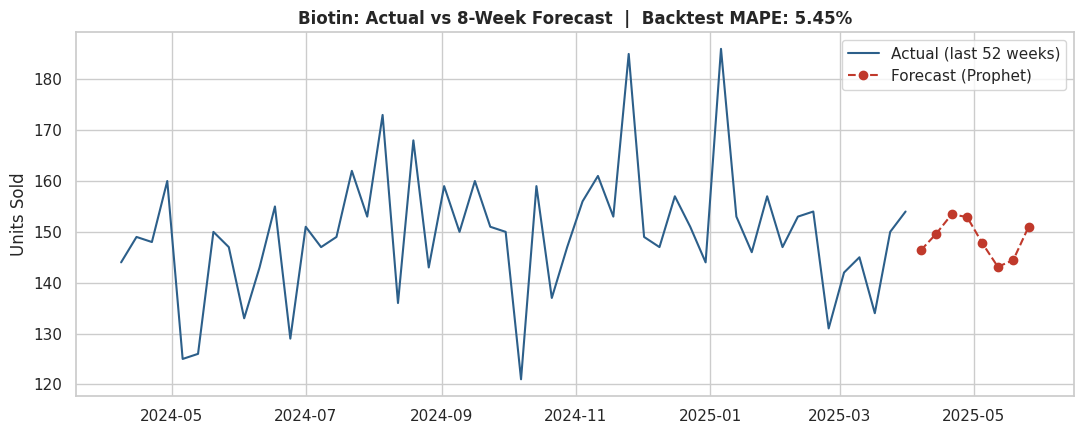

In [ ]:
def plot_product_forecast(product: str):
    prod_hist = df[df["Product Name"] == product].sort_values("Date")
    winner = metrics_table.loc[product, "Best Model"]
    winner_mape = metrics_table.loc[product, "Best MAPE"]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(prod_hist["Date"].iloc[-52:], prod_hist["Units Sold"].iloc[-52:],
            label="Actual (last 52 weeks)", color="#2c5f8a")
    ax.plot(future_dates, forecasts[product], "--o", label=f"Forecast ({winner})", color="#c0392b")
    ax.set_title(f"{product}: Actual vs {TEST_HORIZON}-Week Forecast  |  Backtest MAPE: {winner_mape:.2f}%")
    ax.set_ylabel("Units Sold")
    ax.legend()
    plt.tight_layout()
    plt.show()

# Example: forecast chart for the top-revenue product
example_product = df.groupby("Product Name")["Revenue"].sum().idxmax()
print(f"Example product (highest revenue): {example_product}")
plot_product_forecast(example_product)


In [ ]:
@dataclass
class PlanningInputs:
    avg_weekly_demand: float
    demand_std: float
    lead_time_weeks: float
    service_level: float
    current_inventory: float
    unit_cost: float
    ordering_cost: float = 50.0
    holding_cost_pct: float = 0.20


def z_score(service_level: float) -> float:
    return float(norm.ppf(service_level))


def safety_stock(demand_std: float, lead_time_weeks: float, service_level: float) -> float:
    return z_score(service_level) * demand_std * np.sqrt(max(lead_time_weeks, 0.01))


def reorder_point(avg_weekly_demand: float, lead_time_weeks: float, ss: float) -> float:
    return avg_weekly_demand * lead_time_weeks + ss


def economic_order_quantity(annual_demand, ordering_cost, unit_cost, holding_cost_pct) -> float:
    holding_cost_per_unit = max(unit_cost * holding_cost_pct, 0.01)
    return float(np.sqrt((2 * annual_demand * ordering_cost) / holding_cost_per_unit))


def stockout_probability(current_inventory, avg_weekly_demand, demand_std, lead_time_weeks) -> float:
    lt_demand_mean = avg_weekly_demand * lead_time_weeks
    lt_demand_std = demand_std * np.sqrt(max(lead_time_weeks, 0.01))
    if lt_demand_std <= 0:
        return 0.0 if current_inventory >= lt_demand_mean else 1.0
    z = (current_inventory - lt_demand_mean) / lt_demand_std
    return float(1 - norm.cdf(z))


def run_planning(inputs: PlanningInputs) -> dict:
    ss = safety_stock(inputs.demand_std, inputs.lead_time_weeks, inputs.service_level)
    rop = reorder_point(inputs.avg_weekly_demand, inputs.lead_time_weeks, ss)
    eoq = economic_order_quantity(inputs.avg_weekly_demand * 52, inputs.ordering_cost,
                                  inputs.unit_cost, inputs.holding_cost_pct)
    p_stockout = stockout_probability(inputs.current_inventory, inputs.avg_weekly_demand,
                                      inputs.demand_std, inputs.lead_time_weeks)
    weeks_of_supply = inputs.current_inventory / inputs.avg_weekly_demand if inputs.avg_weekly_demand > 0 else np.inf
    return {
        "safety_stock": round(ss, 1), "reorder_point": round(rop, 1), "eoq": round(eoq, 1),
        "stockout_probability": round(p_stockout * 100, 1),
        "need_to_order": bool(inputs.current_inventory <= rop),
        "weeks_of_supply": round(weeks_of_supply, 1),
    }


def simulate_inventory(forecast, starting_inventory, reorder_qty, rop, lead_time_weeks) -> dict:
    horizon = len(forecast)
    on_hand = np.zeros(horizon)
    stockout_weeks = []
    pending_orders = {}
    inv = starting_inventory
    order_placed = False

    for t in range(horizon):
        if t in pending_orders:
            inv += pending_orders[t]
        inv -= forecast[t]
        if inv < 0:
            stockout_weeks.append(t)
            inv = max(inv, -forecast[t])
        on_hand[t] = inv
        if inv <= rop and not order_placed:
            arrival = t + max(int(round(lead_time_weeks)), 1)
            if arrival < horizon:
                pending_orders[arrival] = pending_orders.get(arrival, 0) + reorder_qty
            order_placed = True

    return {"on_hand": on_hand, "stockout_weeks": stockout_weeks}


print("Planning functions defined (ROP, safety stock, EOQ, stockout probability, simulation).")

Planning functions defined (ROP, safety stock, EOQ, stockout probability, simulation).


In [ ]:
def plan_and_simulate(product: str, lead_time_weeks=2, service_level=0.95,
                      current_inventory=None, ordering_cost=50.0, holding_pct=0.20, verbose=True):
    prod_hist = df[df["Product Name"] == product].sort_values("Date")
    fc_values = np.array(forecasts[product])
    avg_weekly_demand = float(np.mean(fc_values))
    demand_std = float(prod_hist["Units Sold"].iloc[-26:].std())
    asp = float(prod_hist["Price"].iloc[-1])

    if current_inventory is None:
        current_inventory = avg_weekly_demand * 3   # default: ~3 weeks of cover

    inputs = PlanningInputs(
        avg_weekly_demand=avg_weekly_demand, demand_std=demand_std,
        lead_time_weeks=lead_time_weeks, service_level=service_level,
        current_inventory=current_inventory, unit_cost=asp,
        ordering_cost=ordering_cost, holding_cost_pct=holding_pct,
    )
    plan = run_planning(inputs)
    sim = simulate_inventory(fc_values, current_inventory, plan["eoq"], plan["reorder_point"], lead_time_weeks)

    if verbose:
        print(f"--- {product} ---")
        print(f"  Reorder Point (ROP):        {plan['reorder_point']:.0f} units")
        print(f"  Safety Stock:               {plan['safety_stock']:.0f} units")
        print(f"  Economic Order Qty (EOQ):   {plan['eoq']:.0f} units")
        print(f"  Stockout Probability:       {plan['stockout_probability']:.1f}%")
        print(f"  Weeks of Supply on Hand:    {plan['weeks_of_supply']:.1f} wk")
        if plan["need_to_order"]:
            print(f"  ACTION: current inventory ({current_inventory:.0f}) is at/below ROP -- place a PO now.")
        else:
            print(f"  OK: current inventory ({current_inventory:.0f}) is above ROP -- no order needed yet.")

    return plan, sim, fc_values


plan, sim, fc_values = plan_and_simulate(example_product)

--- Biotin ---
  Reorder Point (ROP):        329 units
  Safety Stock:               32 units
  Economic Order Qty (EOQ):   318 units
  Stockout Probability:       0.0%
  Weeks of Supply on Hand:    3.0 wk
  OK: current inventory (446) is above ROP -- no order needed yet.


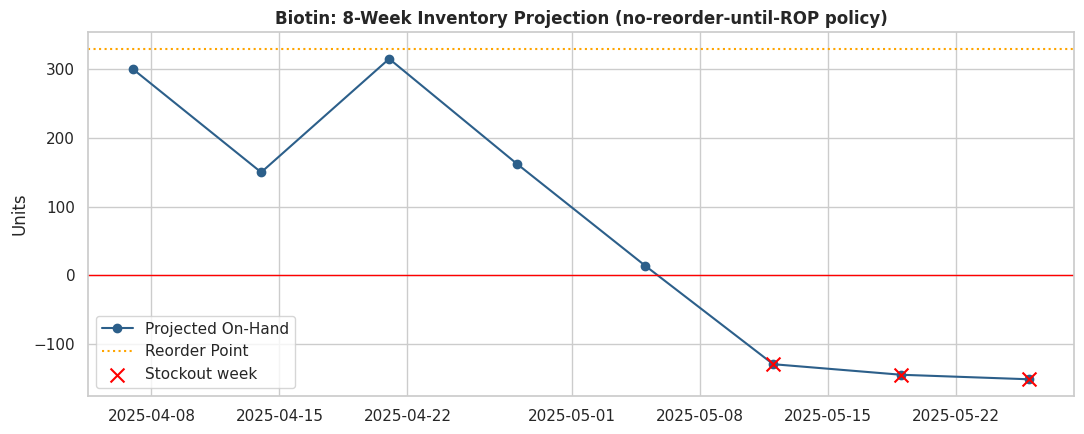

Projected stockout in week(s): 2025-05-12, 2025-05-19, 2025-05-26


,Date,Projected On-Hand,Forecast Demand
0,2025-04-07,299.4,146.4
1,2025-04-14,149.7,149.7
2,2025-04-21,314.7,153.5
3,2025-04-28,161.7,152.9
4,2025-05-05,14.0,147.7
5,2025-05-12,-129.1,143.1
6,2025-05-19,-144.4,144.4
7,2025-05-26,-151.0,151.0


In [ ]:
def plot_inventory_simulation(product: str, plan: dict, sim: dict, fc_values):
    sim_df = pd.DataFrame({
        "Date": future_dates, "Projected On-Hand": sim["on_hand"], "Forecast Demand": fc_values
    })

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(sim_df["Date"], sim_df["Projected On-Hand"], "-o", color="#2c5f8a", label="Projected On-Hand")
    ax.axhline(plan["reorder_point"], color="orange", ls=":", label="Reorder Point")
    ax.axhline(0, color="red", lw=1)
    if sim["stockout_weeks"]:
        sx = [future_dates[i] for i in sim["stockout_weeks"]]
        sy = [sim["on_hand"][i] for i in sim["stockout_weeks"]]
        ax.scatter(sx, sy, color="red", marker="x", s=100, label="Stockout week", zorder=5)
    ax.set_title(f"{product}: {TEST_HORIZON}-Week Inventory Projection (no-reorder-until-ROP policy)")
    ax.set_ylabel("Units")
    ax.legend()
    plt.tight_layout()
    plt.show()

    if sim["stockout_weeks"]:
        dates_str = ", ".join(future_dates[i].strftime("%Y-%m-%d") for i in sim["stockout_weeks"])
        print(f"Projected stockout in week(s): {dates_str}")
    else:
        print("No stockouts projected over the forecast horizon at current settings.")

    return sim_df.round(1)


plot_inventory_simulation(example_product, plan, sim, fc_values)

In [ ]:
# Portfolio-wide planning snapshot: run the default plan for every product
planning_rows = []
for p in products:
    plan_p, sim_p, fc_p = plan_and_simulate(p, verbose=False)
    planning_rows.append({
        "Product": p,
        "Avg Weekly Demand": round(np.mean(fc_p), 1),
        "Reorder Point": plan_p["reorder_point"],
        "Safety Stock": plan_p["safety_stock"],
        "EOQ": plan_p["eoq"],
        "Stockout Prob (%)": plan_p["stockout_probability"],
        "Weeks of Supply": plan_p["weeks_of_supply"],
        "Projected Stockout Weeks": len(sim_p["stockout_weeks"]),
    })

planning_summary = pd.DataFrame(planning_rows).sort_values("Stockout Prob (%)", ascending=False)
planning_summary

,Product,Avg Weekly Demand,Reorder Point,Safety Stock,EOQ,Stockout Prob (%),Weeks of Supply,Projected Stockout Weeks
0,Ashwagandha,147.5,331.6,36.7,256.9,0.0,3.0,4
1,BCAA,150.5,321.8,20.9,404.7,0.0,3.0,3
2,Biotin,148.6,329.1,31.9,318.4,0.0,3.0,3
3,Collagen Peptides,152.1,334.3,30.1,273.7,0.0,3.0,4
4,Creatine,152.5,331.1,26.0,333.6,0.0,3.0,3
5,Electrolyte Powder,149.8,327.4,27.8,315.5,0.0,3.0,3
6,Fish Oil,152.1,334.5,30.2,297.6,0.0,3.0,4
7,Green Tea Extract,150.4,333.8,33.1,437.8,0.0,3.0,3
8,Iron Supplement,148.0,321.4,25.4,458.5,0.0,3.0,2
9,Magnesium,152.2,330.3,25.8,373.0,0.0,3.0,3
